# Step 0 — diagnostics that decide which stimulus-response fix applies

Nothing here is retrained. Every number comes from the existing checkpoints, the clean **active-only** data, and rollouts with the dots **re-anchored** to the simulated fish at each block onset.

| | question | decides |
|---|---|---|
| **D0** | Is the latent model's weaker following caused by the latent or by the head order? | whether fixes go on the plain or the latent model |
| **D1** | Turn law by stimulus geometry: real vs the model's teacher-forced conditional vs free run | under-fit (fix the fit / features) vs compounding (fix the rollout objective) |
| **D2** | The onset transient: P(turn toward) vs time since block onset | whether the block clock is the lever, and how long the real transient is |
| **D3** | Tempo and step size vs time since onset, by condition | whether closing speed is limited by bout rate |

Models: `S1_dta` (plain, the one in the ablation plot), `S3_adt` (plain; its stimulus block carries explicit range-basis × bearing and moving × bearing products) and `S1_adt_z2` (latent, current best); D0 adds plain `S1_adt`.

**Clock note.** The generator's block clock used to be computed from the *generated* time even when the stimulus was read at the *record's* frame (every evaluation rollout since the clock feature existed). Fixed on 2026-09-14 (`RecordAnchoredProvider.clock_s`); the free-run numbers below use the consistent clock.

In [1]:
# Setup: records, models, the model's TEACHER-FORCED turn law on the real bouts, and FREE-RUN
# evaluation rollouts (record-indexed, dots re-anchored). ~4 min.
import sys, json, io, contextlib, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")                      # Model/ -- rollout_model1_local puts ../scripts on the path
import rollout_model1_local
import evaluate as E, fit_MLP as M, fit_MLP_border as MB, fit_MLP_joint as JT, fit_MLP_mix as MX
import generative_metrics as GM
MX._numpy2_unpickle_compat()
ROOT = Path.cwd().parent
REJ = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
BLUE, ORANGE, RED, GREY, GRID = "#2a78d6", "#eb6834", "#b3261e", "#52514e", "#e1e0d9"

MODELS = {"S1":     ("model1_checkpoints",  "S1_dta"),      # the model in the ablation plot
          "S3":     ("model1_checkpoints",  "S3_adt"),      # explicit range-basis x bearing products
          "latent": ("model2z_checkpoints", "S1_adt_z2")}   # current best
R_EVAL = 2                                                  # free-run rollouts per fish per model

d = E.load_bouts()
recs = MB.build_border_records(d)
FISH = sorted(recs)
# block clock and condition per bout, joined on (fish, frame_onset); the record keeps frame_onset
_blk = {f: g.drop_duplicates("frame_onset").set_index("frame_onset")[["t_blk", "cond"]]
        for f, g in d.groupby("fish_id")}
def block_info(f, frame_onset):
    b = _blk[f].reindex(np.asarray(frame_onset, int))
    return b.t_blk.to_numpy(float), b.cond.astype(str).to_numpy()

def held_out(ckdir, arm):
    """fish -> the fold model that never saw it, rej band on."""
    mani = json.loads((Path(ckdir) / "manifest_model1.json").read_text())
    held = {int(f): e["file"] for e in mani if e["file"].startswith(arm + "_fold") for f in e["heldout"]}
    cache = {}
    for ck in set(held.values()):
        m = MX.load_mix(str(Path(ckdir) / ck)); m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ}; cache[ck] = m
    return {f: cache[ck] for f, ck in held.items()}

def conditional(m, r):
    """The model's TEACHER-FORCED turn law on the real bouts: per bout E[dtheta], E|dtheta| and
    P(dtheta > 0) from the angle mixture given the real feature row (and, when the angle head is
    not first, the real step and interval). Latent model: z = 0, the population fish."""
    cf = m._cfg_feat
    X = MB.build_feature_matrix(r, cf)
    az, lc, lt = JT._cond_cols(r.dtheta, r.distance_px, cf["dth_scale"], cf["kin_scales"], y_dt=r.dt_s)
    with torch.no_grad():
        ang = m._model.joint_forward(torch.tensor(X), torch.tensor(az), torch.tensor(lc), torch.tensor(lt))[0]
    w = np.exp(ang[0].numpy())
    sF, aL1, tL1, aL2, tL2, aR1, tR1, aR2, tR2 = [z.numpy().astype(float) for z in ang[1:]]
    m_neg = w[:, 1] * aL1 * tL1 + w[:, 2] * aL2 * tL2      # components 1, 2 emit NEGATIVE dtheta
    m_pos = w[:, 3] * aR1 * tR1 + w[:, 4] * aR2 * tR2      # components 3, 4 emit POSITIVE dtheta
    e_abs = w[:, 0] * sF * np.sqrt(2 / np.pi) + m_neg + m_pos
    return m_pos - m_neg, e_abs, w[:, 3] + w[:, 4] + 0.5 * w[:, 0]

def phi_of(r):                                             # travel-frame bearing, like stim_angle_gen
    p = getattr(r, "stim_angle_travel", None)
    return np.asarray(p if p is not None else r.stim_angle, float)

t0 = time.time()
models = {k: held_out(*v) for k, v in MODELS.items()}
real_rows, cond_rows, gen_rows = [], {k: [] for k in MODELS}, {k: [] for k in MODELS}
for i, f in enumerate(FISH, 1):
    r = recs[f]
    tb, cd = block_info(f, r.frame_onset)
    base = dict(fish=f, t_blk=tb, cond=cd, moving=np.asarray(r.moving, bool))
    real_rows.append(pd.DataFrame(dict(**base, dtheta=r.dtheta, dt=r.dt_s, dist=r.distance_px,
                                       phi=phi_of(r), rng=r.dot_dist_px)))
    for k in MODELS:
        m = models[k][f]
        e_dth, e_abs, p_pos = conditional(m, r)
        cond_rows[k].append(pd.DataFrame(dict(**base, e_dth=e_dth, e_abs=e_abs, p_pos=p_pos,
                                              phi=phi_of(r), rng=r.dot_dist_px)))
        for rep in range(R_EVAL):
            g = m.sample(r, np.random.default_rng([11, f, rep]), **GM._stim_kw(m, r))
            n = len(g["dtheta"])
            gen_rows[k].append(pd.DataFrame(dict(
                fish=f, rep=rep, t_blk=tb[:n], cond=cd[:n], moving=base["moving"][:n],
                dtheta=g["dtheta"], dt=g["dt_s"], dist=g["distance_px"], phi=g["stim_angle_gen"],
                rng=np.hypot(np.asarray(g["x_px"]) - np.asarray(g["dot_cx"]),
                             np.asarray(g["y_px"]) - np.asarray(g["dot_cy"])))))
    print(f"\r  fish {i}/{len(FISH)}   {time.time() - t0:.0f}s", end="", flush=True)
print()
REAL = pd.concat(real_rows, ignore_index=True)
COND = {k: pd.concat(v, ignore_index=True) for k, v in cond_rows.items()}
GEN = {k: pd.concat(v, ignore_index=True) for k, v in gen_rows.items()}
for df in [REAL, *COND.values(), *GEN.values()]:
    df["abs_phi"] = np.degrees(np.abs(df.phi)); df["sgn"] = np.sign(df.phi)
print(f"real {len(REAL):,} bouts | " + " | ".join(f"{k}: conditional {len(COND[k]):,}, free-run {len(GEN[k]):,}"
                                                  for k in MODELS))

  fish 15/15   263s
real 69,572 bouts | S1: conditional 69,572, free-run 139,144 | S3: conditional 69,572, free-run 139,144 | latent: conditional 69,572, free-run 139,144


## D0 — latent or head order?

The latent model was trained with head order `adt`; the plain model in the ablation plot is `dta`. Plain `S1_adt` (same order as the latent, no latent) separates the two. Same construction as the ablation notebook: programme rollouts on the model's own clock, dots re-anchored to the simulated fish at each block onset, 5 fold models × 3 rollouts = 15 simulated fish, centroid-outside-dish bouts dropped on both sides.

  S1_dta (plain): 15 simulated fish  [55s]
  S1_adt (plain, latent's order): 15 simulated fish  [110s]
  S1_adt_z2 (latent): 15 simulated fish  [179s]


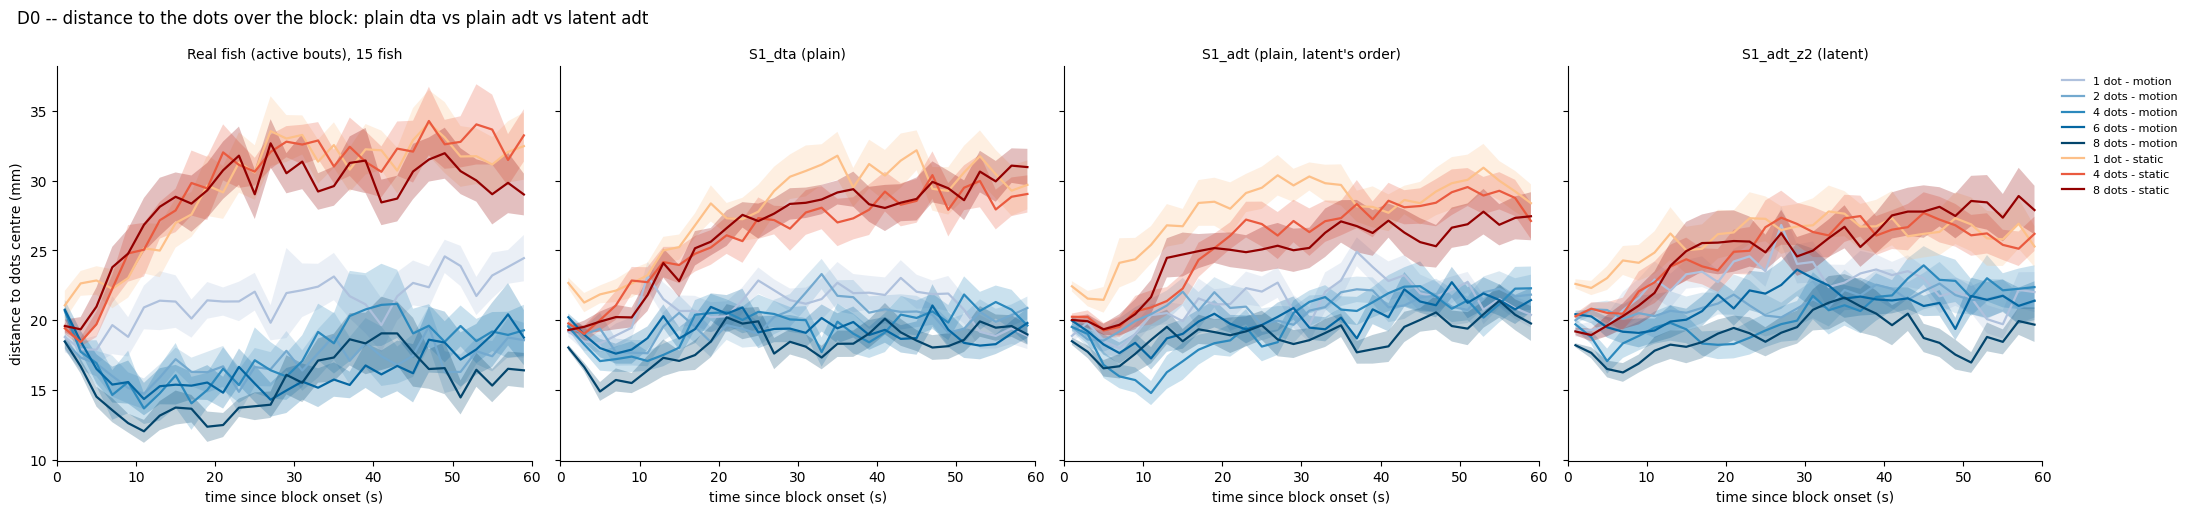

mean distance to the dots, 20-60 s after onset (mm), per-fish mean then mean over fish:
            real  S1_dta  S1_adt  S1_adt_z2
cond_label                                 
d1s3.5      22.4    21.3    22.0       23.0
d2s3.5      17.4    20.5    21.3       21.5
d4s3.5      18.7    20.1    21.0       21.4
d6s3.5      16.7    19.4    20.7       21.7
d8s3.5      16.4    18.9    19.3       19.5
d1s0        31.8    30.0    29.3       26.6
d4s0        31.6    28.1    27.8       26.4
d8s0        30.2    28.8    26.2       26.8

P(turn toward the dots) - 0.5 by dot count, moving blocks (following index):
    real  S1_dta  S1_adt  S1_adt_z2
1  0.076   0.129   0.125      0.105
2  0.122   0.139   0.123      0.104
4  0.133   0.144   0.127      0.106
6  0.150   0.125   0.120      0.118
8  0.135   0.147   0.126      0.126


In [2]:
import stim_program as SP, stim_rollout as SR, tool_reference as TR
PX_TO_MM, BIN_S = 3.67, 2.0
program = SP.load_program(str(ROOT / "assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz"))
dish_sim = SR.default_dish(); ref = TR.load_reference(str(ROOT / "assets/real_reference.npz"))
ORDER = ["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5", "d1s0", "d4s0", "d8s0"]
_pal = lambda name, n: [plt.get_cmap(name)(x) for x in np.linspace(0.35, 0.95, n)]
COLOR = {**dict(zip(ORDER[:5], _pal("PuBu", 5))), **dict(zip(ORDER[5:], _pal("OrRd", 3)))}
LABEL = lambda s: (lambda n: f"{n} dot{'s' if n != '1' else ''} - {'static' if s.endswith('s0') else 'motion'}")(s[1:s.index('s')])

# real side, as in Stimulus_ablation.ipynb
a = d[d.active & (d.stimulus != "inter_stim_pause") & d.dot_dist_px.notna()].copy()
a["n_dots"] = (a.n_dots_left.fillna(0) + a.n_dots_right.fillna(0)).astype(int)
a["cond_label"] = [f"d{n}s{'3.5' if mv else '0'}" for n, mv in zip(a.n_dots, a.moving)]
dish = pd.DataFrame({f: dict(cx=r.dish_cx, cy=r.dish_cy, R=r.dish_R) for f, r in recs.items()}).T
aa = a.join(dish, on="fish_id")
a = a[(np.hypot(aa.dot_cx - aa.cx, aa.dot_cy - aa.cy) <= aa.R).to_numpy()].copy()
a["dist_mm"] = a.dot_dist_px / PX_TO_MM; a["tbin"] = (np.floor(a.t_blk / BIN_S) + .5) * BIN_S
a["unit"] = a.fish_id

ARMS3 = [("S1_dta (plain)", "model1_checkpoints", "S1_dta"),
         ("S1_adt (plain, latent's order)", "model1_checkpoints", "S1_adt"),
         ("S1_adt_z2 (latent)", "model2z_checkpoints", "S1_adt_z2")]
def programme_rollouts(ckdir, arm, per_model=3):
    folds = sorted(e["file"] for e in json.loads((Path(ckdir) / "manifest_model1.json").read_text())
                   if e["file"].startswith(arm + "_fold"))
    rows = []
    for k, ck in enumerate(folds):
        m = MX.load_mix(str(Path(ckdir) / ck)); m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ}
        with contextlib.redirect_stdout(io.StringIO()):
            rolls = SR.rollout_many(m, program, per_model, seed=k, dish=dish_sim, pose_sampler=ref.sample_start_pose)
        for r_, g in enumerate(rolls):
            b = np.asarray(g["block_id"])
            rows.append(pd.DataFrame(dict(
                unit=k * per_model + r_, t_blk=(np.asarray(g["frame_onset"]) - program.starts[b]) / program.fps,
                is_stim=program.is_stim_of[b], n_dots=program.n_dots_of[b], moving=program.moving_of[b],
                gx=g["x_px"], gy=g["y_px"], gcx=g["dot_cx"], gcy=g["dot_cy"],
                dtheta=g["dtheta"], dt=g["dt_s"], phi=g["stim_angle_gen"])))
    s = pd.concat(rows, ignore_index=True)
    s = s[s.is_stim & s.gcx.notna()].copy()
    s["cond_label"] = [f"d{int(n)}s{'3.5' if mv else '0'}" for n, mv in zip(s.n_dots, s.moving)]
    s = s[(np.hypot(s.gcx - dish_sim[0], s.gcy - dish_sim[1]) <= dish_sim[2]).to_numpy()].copy()
    s["dist_mm"] = np.hypot(s.gx - s.gcx, s.gy - s.gcy) / PX_TO_MM
    s["tbin"] = (np.floor(s.t_blk / BIN_S) + .5) * BIN_S
    return s
t0 = time.time()
SIM = {}
for lab, ck, arm in ARMS3:
    SIM[lab] = programme_rollouts(ck, arm); print(f"  {lab}: {SIM[lab].unit.nunique()} simulated fish  [{time.time()-t0:.0f}s]")

fig, ax = plt.subplots(1, 4, figsize=(22, 5.2), sharey=True)
for axi, (title, df) in zip(ax, [("Real fish (active bouts), 15 fish", a)] + [(lab, SIM[lab]) for lab, *_ in ARMS3]):
    for s_ in ORDER:
        pf = df[df.cond_label == s_].groupby(["unit", "tbin"]).dist_mm.mean().reset_index().groupby("tbin").dist_mm
        mu, sem = pf.mean(), pf.sem()
        axi.plot(mu.index, mu, color=COLOR[s_], lw=1.6, label=LABEL(s_))
        axi.fill_between(mu.index, mu - sem, mu + sem, color=COLOR[s_], alpha=.25, edgecolor="none")
    axi.set_title(title, fontsize=10); axi.set_xlim(0, 60); axi.set_xlabel("time since block onset (s)")
    axi.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("distance to dots centre (mm)")
ax[-1].legend(fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("D0 -- distance to the dots over the block: plain dta vs plain adt vs latent adt", x=.01, ha="left")
plt.tight_layout(); plt.show()

def late(df, lo=20, hi=60):
    w = df[(df.t_blk >= lo) & (df.t_blk < hi)]
    return w.groupby(["cond_label", "unit"]).dist_mm.mean().groupby("cond_label").mean()
print("mean distance to the dots, 20-60 s after onset (mm), per-fish mean then mean over fish:")
print(pd.DataFrame({"real": late(a), **{lab.split(" ")[0]: late(SIM[lab]) for lab, *_ in ARMS3}}).loc[ORDER].round(1).to_string())
print("\nP(turn toward the dots) - 0.5 by dot count, moving blocks (following index):")
fi = {"real": {k: round(float(v) - 0.5, 3) for k, v in ref.curves["following_by_n"].items()}}
for lab, *_ in ARMS3:
    s_ = SIM[lab]
    fi[lab.split(" ")[0]] = {k: round(float(v) - 0.5, 3) for k, v in
                             TR.following_by_n(s_.dtheta.to_numpy(), s_.phi.to_numpy(), s_.n_dots.to_numpy(),
                                               s_.moving.to_numpy(float)).items()}
print(pd.DataFrame(fi).to_string())

## D1 — the turn law by stimulus geometry: real vs conditional vs free run

Three versions of the same statistics, in bins of |bearing| × range on bouts with a dot present:

- **real**: the real bouts.
- **conditional**: what the model *predicts* on those same real bouts (teacher-forced: the model's angle mixture given the real feature row). This is the fit itself, with no rollout involved.
- **free run**: the model's own rollouts, binned by the bearing and range *it* saw.

"Toward" = Δθ · sign(φ), positive when the turn goes toward the dots (travel frame on both sides). Reading rule: **conditional ≈ real but free run ≠ real → the fit is right and the rollout compounds** (exposure bias); **conditional ≠ real → the fit itself is off** (under-fit or the features can't express it). The panel's `tuning_mse` / `following_gap` only score the sign; the *mean toward turn* column is the magnitude they can't see.

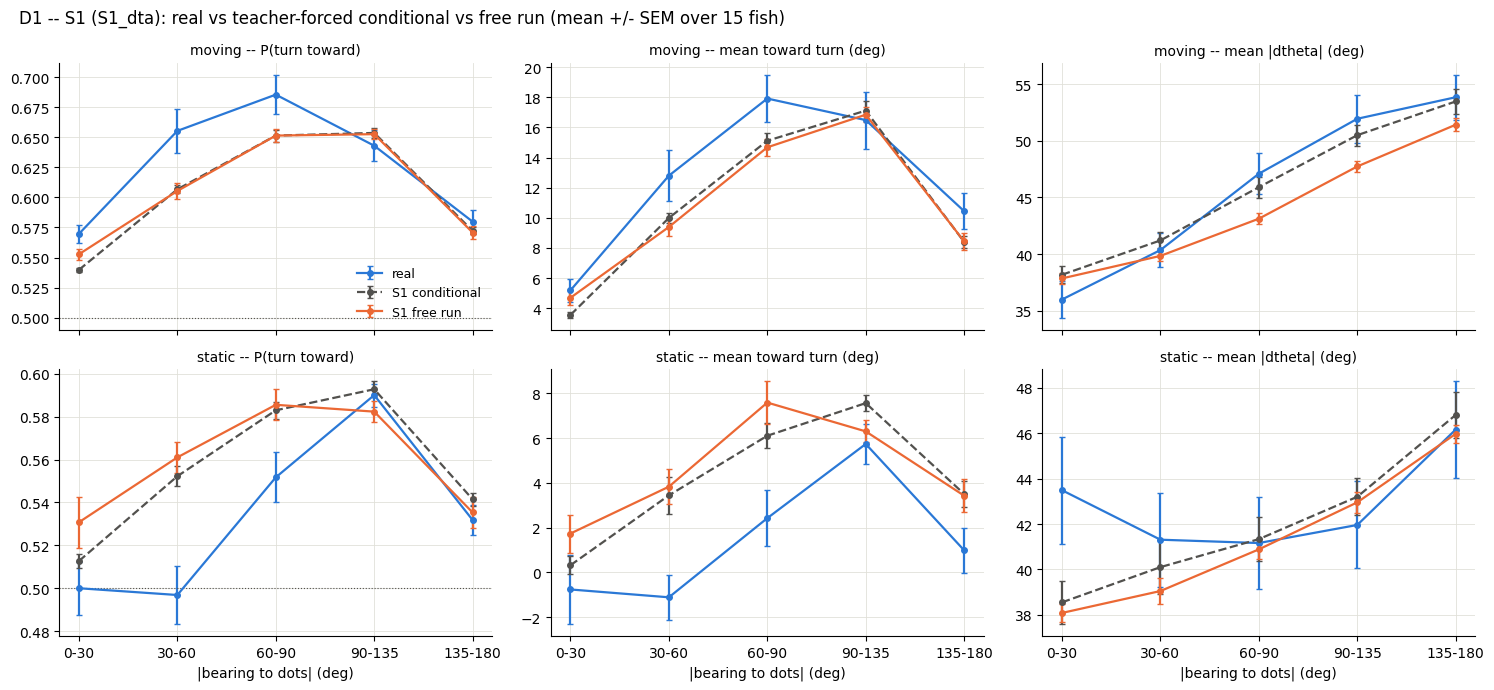

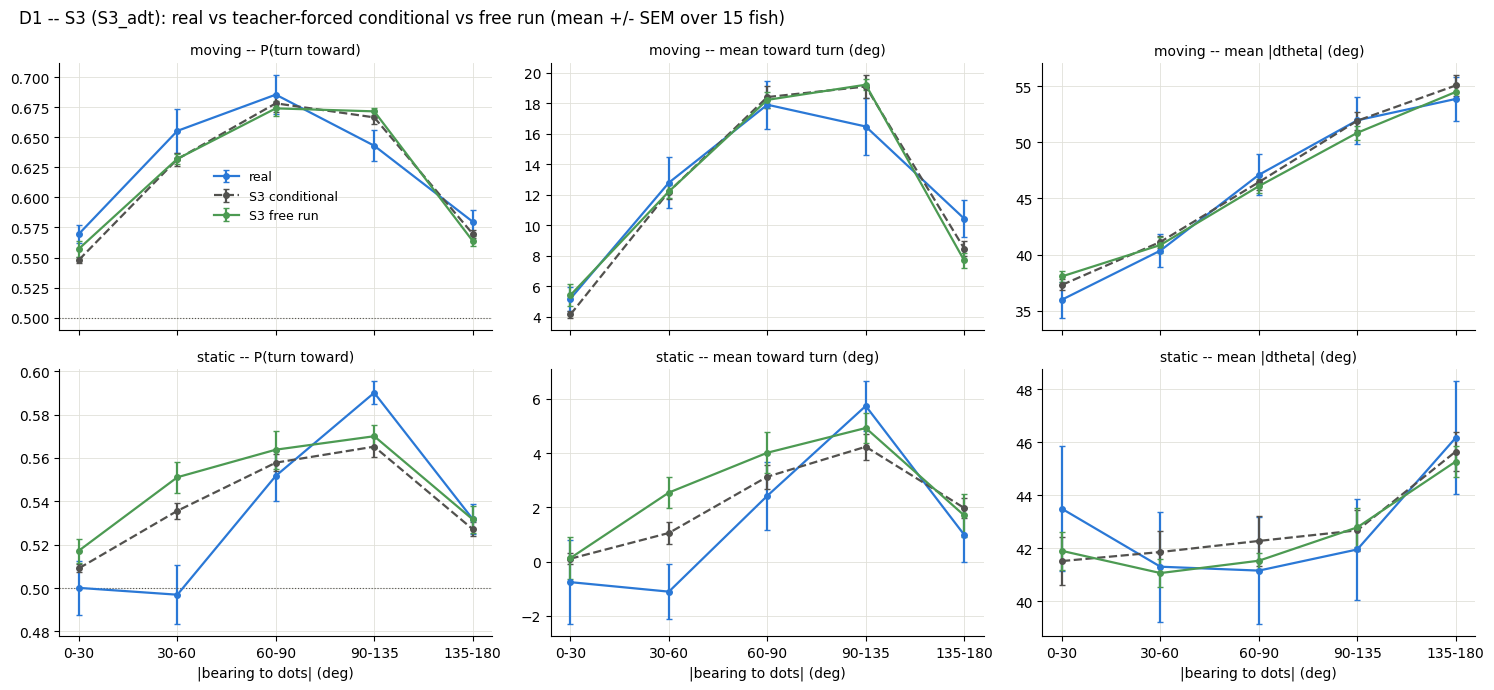

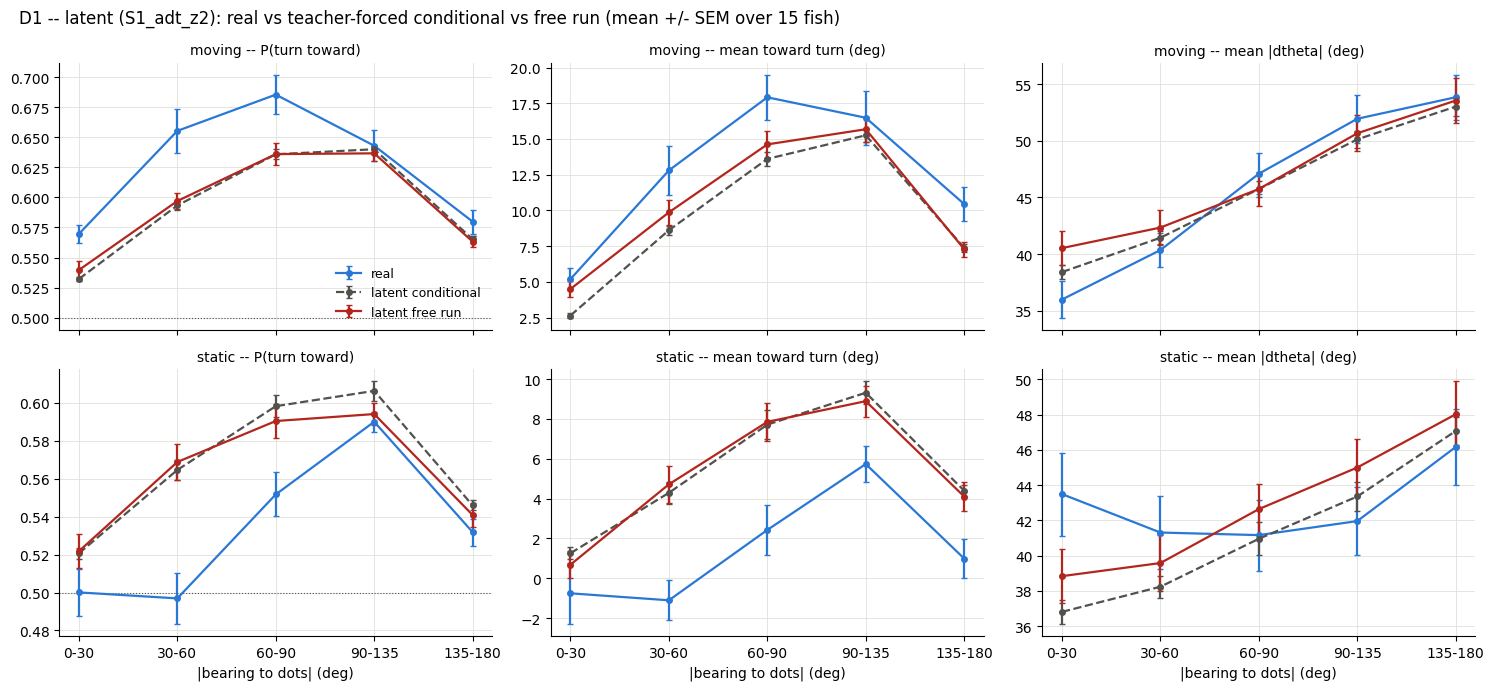

MOVING blocks, mean toward turn (deg): rows |bearing|, columns range to the dots

  real
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        6.6    5.8     5.8   4.2
30-60       6.0   16.1    19.1  13.6
60-90       8.6   23.3    25.0  13.5
90-135     10.9   21.5    19.3   9.1
135-180     9.4   16.7     6.0   3.7

  S1 conditional
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        3.4    3.6     3.6   3.7
30-60      10.0    9.8    10.3  10.4
60-90      15.0   15.3    13.7  14.1
90-135     16.9   17.4    17.8  16.3
135-180     8.1    9.1     8.1   7.6

  S1 free run
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        6.0    4.4     3.8   4.8
30-60       8.7    8.8    10.5  11.5
60-90      12.9   15.3    15.5  13.6
90-135     17.6   16.5    17.6  16.3
135-180     9.7    8.2     7.4   8.9

  S3 conditional
rb       <40 px  40-80  80-120  >120
bb                                  
0-30     

In [3]:
B_EDGES, B_LAB = [0, 30, 60, 90, 135, 180.01], ["0-30", "30-60", "60-90", "90-135", "135-180"]
R_EDGES, R_LAB = [0, 40, 80, 120, 1e9], ["<40 px", "40-80", "80-120", ">120"]
MCOL = {"S1": ORANGE, "S3": "#4c9a52", "latent": RED}
STATS = [("p_tw", "P(turn toward)"), ("toward", "mean toward turn (deg)"), ("absd", "mean |dtheta| (deg)")]

def turn_stats(df, is_cond):
    x = df[df.phi.notna() & df.rng.notna() & (df.sgn != 0)].copy()
    x["bb"] = pd.cut(x.abs_phi, B_EDGES, labels=B_LAB, right=False)
    x["rb"] = pd.cut(x.rng, R_EDGES, labels=R_LAB, right=False)
    if is_cond:
        x["toward"] = x.e_dth * x.sgn; x["absd"] = x.e_abs
        x["p_tw"] = np.where(x.sgn > 0, x.p_pos, 1 - x.p_pos)
    else:
        x["toward"] = x.dtheta * x.sgn; x["absd"] = x.dtheta.abs(); x["p_tw"] = (x.toward > 0).astype(float)
    return x

def per_fish(x, by):
    return x.groupby(list(by) + ["fish"], observed=True)[["p_tw", "toward", "absd"]].mean().reset_index()

SRC = {"real": turn_stats(REAL, False)}
for k in MODELS:
    SRC[f"{k} conditional"] = turn_stats(COND[k], True); SRC[f"{k} free run"] = turn_stats(GEN[k], False)

for k in MODELS:
    fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for row, mv in enumerate([True, False]):
        for col, (st_, lab) in enumerate(STATS):
            axx = ax[row, col]
            for name, color, ls in [("real", BLUE, "-"), (f"{k} conditional", GREY, "--"), (f"{k} free run", MCOL[k], "-")]:
                pf = per_fish(SRC[name][SRC[name].moving == mv], ["bb"])
                g = pf.groupby("bb", observed=True)[st_]
                mu, se = g.mean().reindex(B_LAB), g.sem().reindex(B_LAB)
                xx = np.arange(len(B_LAB))
                axx.errorbar(xx, mu, yerr=se, color=color, ls=ls, marker="o", ms=4, capsize=2, lw=1.6, label=name)
            axx.set_xticks(np.arange(len(B_LAB))); axx.set_xticklabels(B_LAB)
            axx.set_title(f"{'moving' if mv else 'static'} -- {lab}", fontsize=10)
            axx.grid(color=GRID, lw=.6); axx.set_axisbelow(True); axx.spines[["top", "right"]].set_visible(False)
            if st_ == "p_tw": axx.axhline(.5, color=GREY, lw=.8, ls=":")
    for axx in ax[1]: axx.set_xlabel("|bearing to dots| (deg)")
    ax[0, 0].legend(frameon=False, fontsize=9)
    fig.suptitle(f"D1 -- {k} ({MODELS[k][1]}): real vs teacher-forced conditional vs free run (mean +/- SEM over 15 fish)",
                 x=.01, ha="left")
    plt.tight_layout(); plt.show()

print("MOVING blocks, mean toward turn (deg): rows |bearing|, columns range to the dots")
for name in SRC:
    pf = per_fish(SRC[name][SRC[name].moving], ["bb", "rb"])
    tab = pf.groupby(["bb", "rb"], observed=True).toward.mean().unstack("rb").reindex(index=B_LAB, columns=R_LAB)
    print(f"\n  {name}"); print(tab.round(1).to_string())
print("\nSummary on moving bouts with the dots lateral (|bearing| 60-135 deg), all ranges:")
rows = []
for name in SRC:
    x = SRC[name]; x = x[x.moving & x.bb.isin(["60-90", "90-135"])]
    pf = x.groupby("fish")[["p_tw", "toward", "absd"]].mean()
    rows.append(dict(source=name, **{lab: f"{pf[st_].mean():.3f} +/- {pf[st_].sem():.3f}" for st_, lab in STATS}))
print(pd.DataFrame(rows).set_index("source").to_string())

## D2 — the onset transient

The block clock (`exp(−t/4 s)`) was built from a measured step: at matched geometry (range 40–85 px, |bearing| 45–135°) real fish turn toward moving dots with P = 0.80 in the first 5 s of a block against 0.70 afterwards. Two questions: does the model reproduce that step in free run, and how long is the real transient once binned at 2 s? Free-run bouts inherit the block time of the real bout they stand in for (the provider reads the record's frame), so the bins line up exactly on both sides.

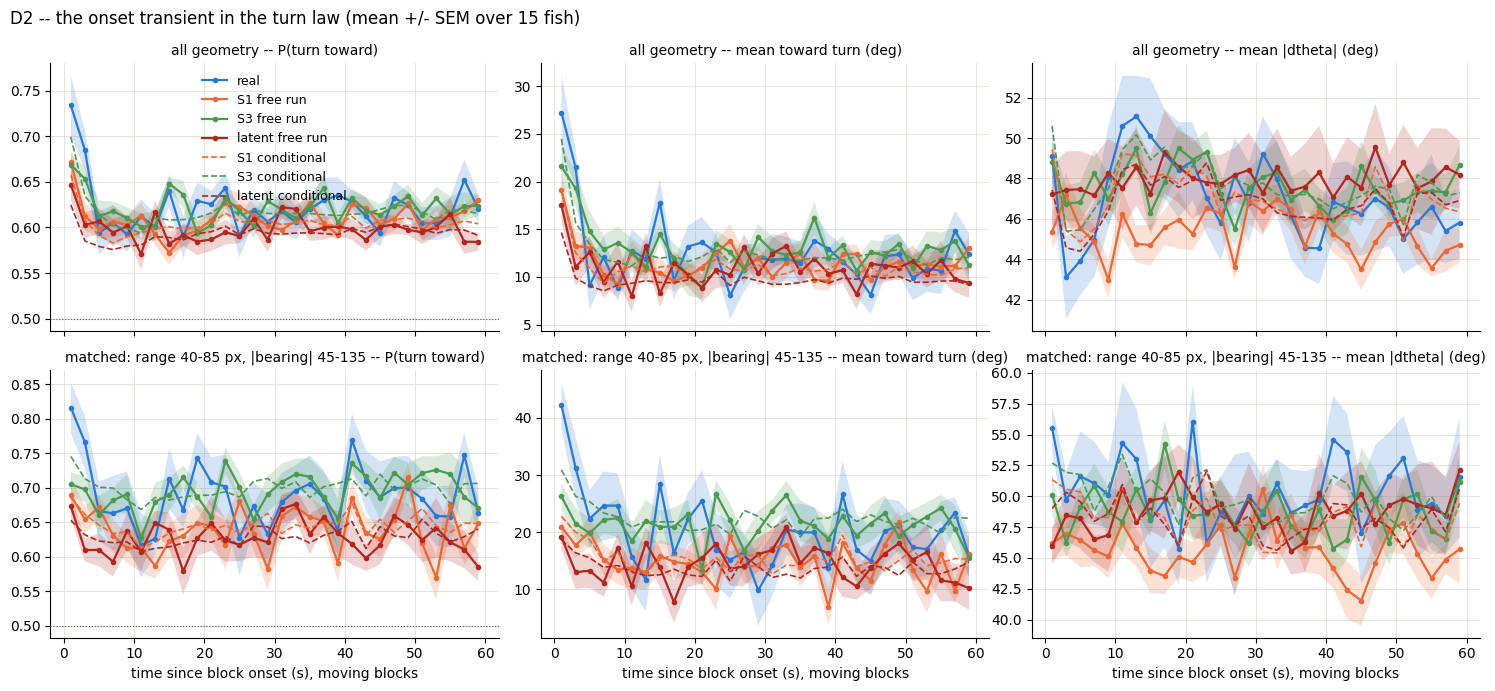

P(turn toward), matched geometry: first 4 s vs 10-60 s, and how long the excess lasts
  real             first 4 s 0.791   10-60 s 0.683   step +0.107   last 2 s-bin above the late level (+1 SEM): 18-20 s
  S1 free run      first 4 s 0.671   10-60 s 0.637   step +0.034   last 2 s-bin above the late level (+1 SEM): 4-6 s
  S3 free run      first 4 s 0.701   10-60 s 0.696   step +0.005   last 2 s-bin above the late level (+1 SEM): None
  latent free run  first 4 s 0.641   10-60 s 0.629   step +0.012   last 2 s-bin above the late level (+1 SEM): 0-2 s
  S1 conditional   first 4 s 0.673   10-60 s 0.644   step +0.029   last 2 s-bin above the late level (+1 SEM): 2-4 s
  S3 conditional   first 4 s 0.729   10-60 s 0.697   step +0.032   last 2 s-bin above the late level (+1 SEM): 2-4 s
  latent conditional first 4 s 0.642   10-60 s 0.629   step +0.013   last 2 s-bin above the late level (+1 SEM): 0-2 s


In [4]:
T_EDGES = np.arange(0, 62, 2); T_MID = T_EDGES[:-1] + 1.0
def onset_profile(df, matched, is_cond=False):
    x = df[df.moving & df.phi.notna() & df.rng.notna() & df.t_blk.notna() & (df.sgn != 0)].copy()
    if matched:
        x = x[(x.rng >= 40) & (x.rng <= 85) & (x.abs_phi >= 45) & (x.abs_phi <= 135)]
    x["tb"] = pd.cut(x.t_blk, T_EDGES, right=False, labels=T_MID)
    if is_cond:                      # the model's teacher-forced law on the real bouts
        x["toward"] = x.e_dth * x.sgn; x["absd"] = x.e_abs; x["p_tw"] = np.where(x.sgn > 0, x.p_pos, 1 - x.p_pos)
    else:
        x["toward"] = x.dtheta * x.sgn; x["absd"] = x.dtheta.abs(); x["p_tw"] = (x.toward > 0).astype(float)
    per = x.groupby(["tb", "fish"], observed=True)[["p_tw", "toward", "absd"]].mean().reset_index()
    g = per.groupby("tb", observed=True)[["p_tw", "toward", "absd"]]
    return g.mean().reindex(T_MID), g.sem().reindex(T_MID)

LINES = [("real", REAL, BLUE)] + [(f"{k} free run", GEN[k], MCOL[k]) for k in MODELS]
CLINES = [(f"{k} conditional", COND[k], MCOL[k]) for k in MODELS]
fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for row, matched in enumerate([False, True]):
    for col, (st_, lab) in enumerate(STATS):
        axx = ax[row, col]
        for name, df, color in LINES:
            mu, se = onset_profile(df, matched)
            axx.plot(T_MID, mu[st_], color=color, lw=1.6, marker="o", ms=3, label=name)
            axx.fill_between(T_MID, mu[st_] - se[st_], mu[st_] + se[st_], color=color, alpha=.2, edgecolor="none")
        for name, df, color in CLINES:   # teacher-forced: did the fit learn the onset at all?
            mu, _ = onset_profile(df, matched, is_cond=True)
            axx.plot(T_MID, mu[st_], color=color, lw=1.2, ls="--", label=name)
        axx.set_title(("all geometry" if not matched else "matched: range 40-85 px, |bearing| 45-135") + f" -- {lab}", fontsize=10)
        axx.grid(color=GRID, lw=.6); axx.set_axisbelow(True); axx.spines[["top", "right"]].set_visible(False)
        if st_ == "p_tw": axx.axhline(.5, color=GREY, lw=.8, ls=":")
for axx in ax[1]: axx.set_xlabel("time since block onset (s), moving blocks")
ax[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("D2 -- the onset transient in the turn law (mean +/- SEM over 15 fish)", x=.01, ha="left")
plt.tight_layout(); plt.show()

print("P(turn toward), matched geometry: first 4 s vs 10-60 s, and how long the excess lasts")
for name, df, _ in LINES + CLINES:
    mu, se = onset_profile(df, True, is_cond=name.endswith("conditional"))
    early, late_ = mu.p_tw.iloc[:2].mean(), mu.p_tw.iloc[5:].mean()
    late_se = se.p_tw.iloc[5:].mean()
    above = [t for t, v in zip(T_MID, mu.p_tw) if v > late_ + late_se]
    end = max([t for t in above if t <= 20], default=None)
    print(f"  {name:<16} first 4 s {early:.3f}   10-60 s {late_:.3f}   step {early - late_:+.3f}   "
          f"last 2 s-bin above the late level (+1 SEM): {end if end is None else f'{end - 1:.0f}-{end + 1:.0f} s'}")

## D3 — tempo and step size vs time since onset

If real fish bout faster or take larger steps right after a stimulus appears and the model doesn't, closing speed is limited by tempo rather than by the turn law, and that is where a clock feature would act. Per-fish **medians** in 2 s bins (intervals are heavy-tailed), then mean ± SEM over fish. `none` = the inter-stimulus pause (time since the pause started).

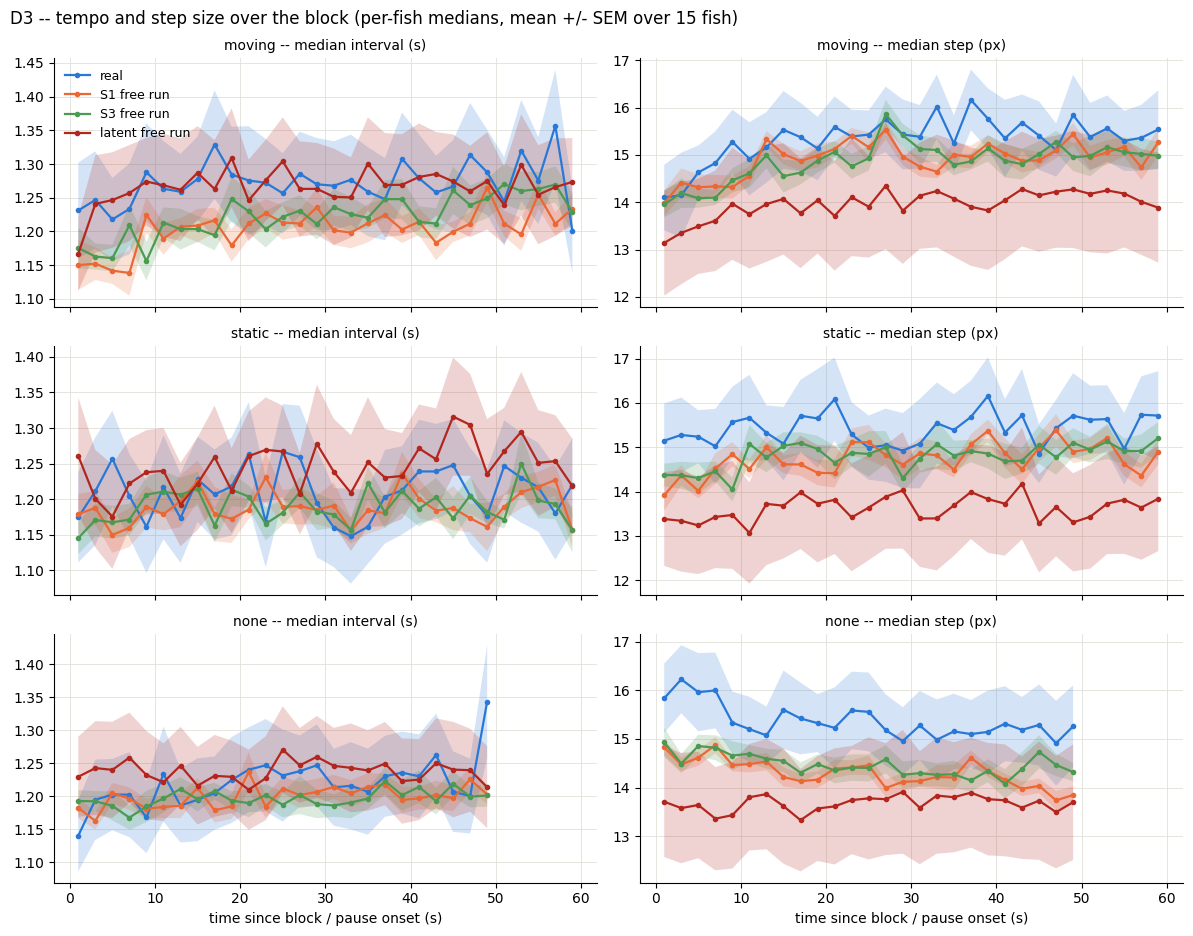

first 4 s vs 10-60 s of the block, per-fish medians averaged over fish:
                        dt_first4  dt_late  step_first4  step_late
cond   source                                                     
moving real                 1.239    1.277       14.124     15.474
       S1 free run          1.151    1.213       14.197     15.043
       S3 free run          1.169    1.232       14.075     14.994
       latent free run      1.204    1.272       13.246     14.045
static real                 1.193    1.211       15.212     15.452
       S1 free run          1.183    1.191       14.139     14.820
       S3 free run          1.158    1.193       14.370     14.896
       latent free run      1.231    1.249       13.359     13.672
none   real                 1.167    1.229       16.031     15.238
       S1 free run          1.172    1.203       14.652     14.210
       S3 free run          1.192    1.200       14.713     14.399
       latent free run      1.236    1.236       13.646  

In [5]:
def tempo_profile(df, cond):
    x = df[(df.cond == cond) & df.t_blk.notna()].copy()
    x["tb"] = pd.cut(x.t_blk, T_EDGES, right=False, labels=T_MID)
    per = x.groupby(["tb", "fish"], observed=True)[["dt", "dist"]].median().reset_index()
    g = per.groupby("tb", observed=True)[["dt", "dist"]]
    return g.mean().reindex(T_MID), g.sem().reindex(T_MID)

fig, ax = plt.subplots(3, 2, figsize=(12, 9.5), sharex=True)
for row, cond in enumerate(["moving", "static", "none"]):
    for col, (st_, lab) in enumerate([("dt", "median interval (s)"), ("dist", "median step (px)")]):
        axx = ax[row, col]
        for name, df, color in LINES:
            mu, se = tempo_profile(df, cond)
            axx.plot(T_MID, mu[st_], color=color, lw=1.6, marker="o", ms=3, label=name)
            axx.fill_between(T_MID, mu[st_] - se[st_], mu[st_] + se[st_], color=color, alpha=.2, edgecolor="none")
        axx.set_title(f"{cond} -- {lab}", fontsize=10)
        axx.grid(color=GRID, lw=.6); axx.set_axisbelow(True); axx.spines[["top", "right"]].set_visible(False)
for axx in ax[2]: axx.set_xlabel("time since block / pause onset (s)")
ax[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("D3 -- tempo and step size over the block (per-fish medians, mean +/- SEM over 15 fish)", x=.01, ha="left")
plt.tight_layout(); plt.show()

print("first 4 s vs 10-60 s of the block, per-fish medians averaged over fish:")
rows = []
for cond in ["moving", "static", "none"]:
    for name, df, _ in LINES:
        mu, _ = tempo_profile(df, cond)
        rows.append(dict(cond=cond, source=name, dt_first4=mu.dt.iloc[:2].mean(), dt_late=mu.dt.iloc[5:].mean(),
                         step_first4=mu["dist"].iloc[:2].mean(), step_late=mu["dist"].iloc[5:].mean()))
print(pd.DataFrame(rows).set_index(["cond", "source"]).round(3).to_string())

## D4 — per-bout closing rate

The distance curve is the integral of what happens bout by bout. This is the mean change in range to the dots over the next bout, by range × |bearing| bin, moving blocks; positive = the fish got closer (the dots move too, identically on both sides). If a model's map matches real but its distance curve does not, the difference is in *which states it visits* (e.g. the onset), not in its per-bout dynamics.

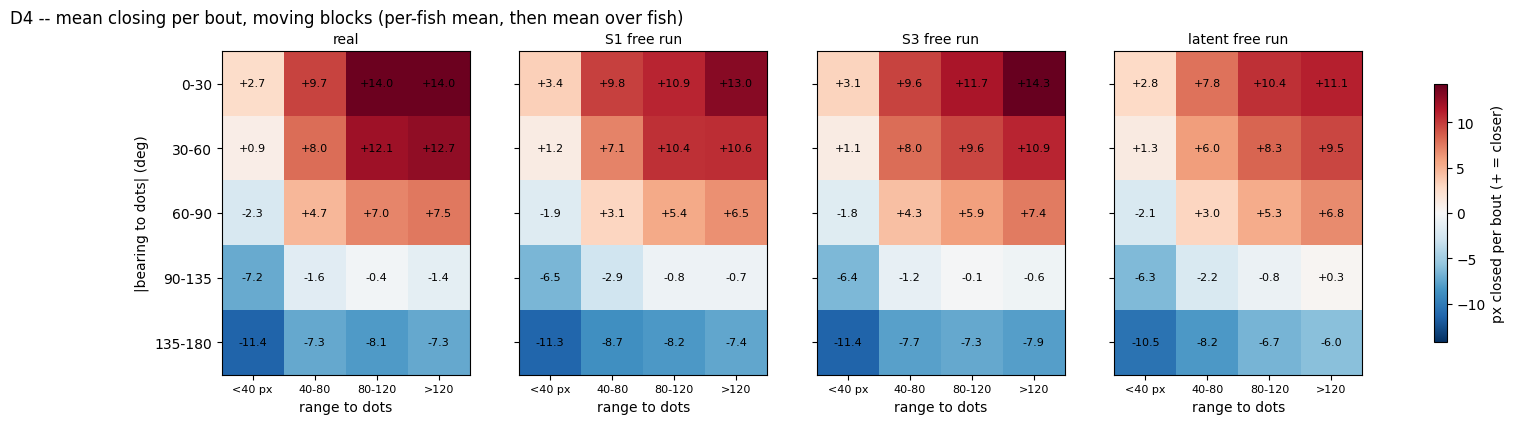

closing per bout (px), MOVING -- per-fish mean then mean over fish:
real
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        2.7    9.7    14.0  14.0
30-60       0.9    8.0    12.1  12.7
60-90      -2.3    4.7     7.0   7.5
90-135     -7.2   -1.6    -0.4  -1.4
135-180   -11.4   -7.3    -8.1  -7.3
S1 free run
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        3.4    9.8    10.9  13.0
30-60       1.2    7.1    10.4  10.6
60-90      -1.9    3.1     5.4   6.5
90-135     -6.5   -2.9    -0.8  -0.7
135-180   -11.3   -8.7    -8.2  -7.4
S3 free run
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        3.1    9.6    11.7  14.3
30-60       1.1    8.0     9.6  10.9
60-90      -1.8    4.3     5.9   7.4
90-135     -6.4   -1.2    -0.1  -0.6
135-180   -11.4   -7.7    -7.3  -7.9
latent free run
rb       <40 px  40-80  80-120  >120
bb                                  
0-30        2.8    7.8    10.4  11.1

In [6]:
def closing(df):
    x = df.copy()
    key = ["fish"] + (["rep"] if "rep" in x.columns else [])
    x["rng_next"] = x.groupby(key).rng.shift(-1); x["t_next"] = x.groupby(key).t_blk.shift(-1)
    # consecutive bouts inside the same block (t_blk increases), both with a dot on screen
    x = x[x.moving & x.rng.notna() & x.rng_next.notna() & x.phi.notna() & (x.sgn != 0) & (x.t_next > x.t_blk)].copy()
    x["close"] = x.rng - x.rng_next
    x["bb"] = pd.cut(x.abs_phi, B_EDGES, labels=B_LAB, right=False); x["rb"] = pd.cut(x.rng, R_EDGES, labels=R_LAB, right=False)
    pf = x.groupby(["bb", "rb", "fish"], observed=True).close.mean().reset_index()
    return pf.groupby(["bb", "rb"], observed=True).close.mean().unstack("rb").reindex(index=B_LAB, columns=R_LAB)

MAPS = {"real": closing(REAL), **{f"{k} free run": closing(GEN[k]) for k in MODELS}}
fig, ax = plt.subplots(1, len(MAPS), figsize=(4.6 * len(MAPS), 4.2), sharey=True)
vmax = max(np.nanmax(np.abs(m.values)) for m in MAPS.values())
for axi, (name, m) in zip(ax, MAPS.items()):
    im = axi.imshow(m.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    axi.set_xticks(range(len(R_LAB))); axi.set_xticklabels(R_LAB, fontsize=8); axi.set_xlabel("range to dots")
    axi.set_title(name, fontsize=10)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            if np.isfinite(v): axi.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8)
ax[0].set_yticks(range(len(B_LAB))); ax[0].set_yticklabels(B_LAB); ax[0].set_ylabel("|bearing to dots| (deg)")
fig.colorbar(im, ax=ax, shrink=.8, label="px closed per bout (+ = closer)")
fig.suptitle("D4 -- mean closing per bout, moving blocks (per-fish mean, then mean over fish)", x=.01, ha="left")
plt.show()
print("closing per bout (px), MOVING -- per-fish mean then mean over fish:")
for name, m in MAPS.items():
    print(f"{name}")
    print(m.round(1).to_string())

## D5 — what the closing shortfall is made of

D4 says the models close 2–3 px less per bout only when the dots are **ahead** (|bearing| < 60°) and **≥ 80 px** away. Closing per bout is (step size) × (how well the bout points at the dots) minus the dots' own motion, so the shortfall sits in one of two heads: the **distance head** (real fish lengthen their bouts when heading at the dots) or the **turn head** (real fish turn less when already aligned). Median step and mean |Δθ| in the same bins, real vs free run.

median step (px), MOVING, rows |bearing| x columns range -- per-fish median then mean over fish
  real
rb       <40 px  40-80  80-120  >120
bb                                  
0-30       15.4   14.6    15.8  16.7
30-60      15.3   14.8    15.5  16.6
60-90      15.3   14.8    14.2  17.1
90-135     15.6   14.9    14.5  16.2
135-180    16.0   15.2    15.3  15.7
  S1 free run
rb       <40 px  40-80  80-120  >120
bb                                  
0-30       15.6   14.6    14.5  15.5
30-60      15.7   14.5    15.2  15.1
60-90      15.4   14.4    14.5  15.2
90-135     15.3   14.8    14.6  15.6
135-180    15.2   14.8    14.7  14.9
  S3 free run
rb       <40 px  40-80  80-120  >120
bb                                  
0-30       15.6   14.5    14.6  15.8
30-60      15.3   14.7    14.1  15.6
60-90      15.2   14.3    14.2  15.5
90-135     15.4   14.6    14.4  15.1
135-180    15.7   15.2    14.4  15.2
  latent free run
rb       <40 px  40-80  80-120  >120
bb                                  


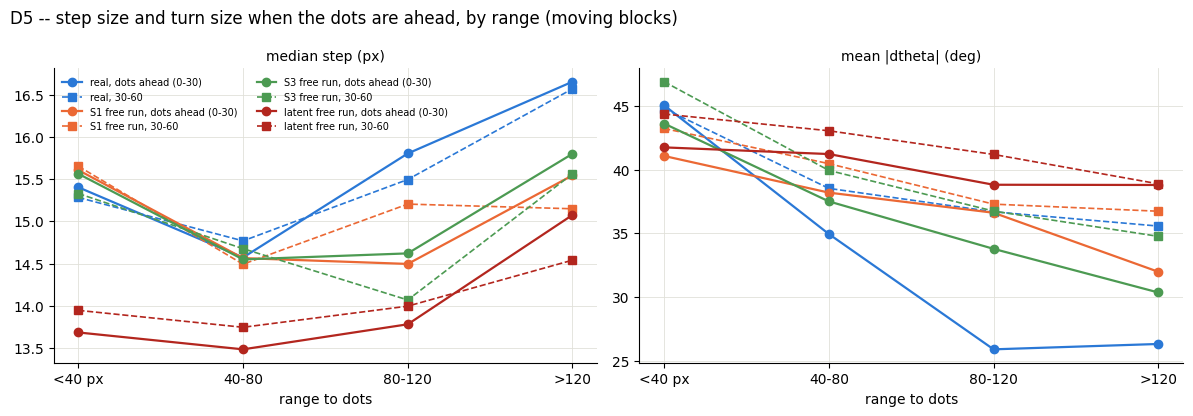

In [7]:
def geom_table(df, col, how):
    x = df[df.moving & df.phi.notna() & df.rng.notna() & (df.sgn != 0)].copy()
    x["bb"] = pd.cut(x.abs_phi, B_EDGES, labels=B_LAB, right=False); x["rb"] = pd.cut(x.rng, R_EDGES, labels=R_LAB, right=False)
    v = x[col].abs() if col == "dtheta" else x[col]
    x = x.assign(v=v)
    pf = x.groupby(["bb", "rb", "fish"], observed=True).v.agg(how).reset_index()
    return pf.groupby(["bb", "rb"], observed=True).v.mean().unstack("rb").reindex(index=B_LAB, columns=R_LAB)

SRC5 = {"real": REAL, **{f"{k} free run": GEN[k] for k in MODELS}}
for col, how, lab in [("dist", "median", "median step (px)"), ("dtheta", "mean", "mean |dtheta| (deg)")]:
    print(f"{lab}, MOVING, rows |bearing| x columns range -- per-fish {how} then mean over fish")
    for name, df in SRC5.items():
        print(f"  {name}"); print(geom_table(df, col, how).round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for axi, (col, how, lab) in zip(ax, [("dist", "median", "median step (px)"), ("dtheta", "mean", "mean |dtheta| (deg)")]):
    for name, df in SRC5.items():
        t = geom_table(df, col, how)
        color = BLUE if name == "real" else MCOL[name.split(" ")[0]]
        axi.plot(range(len(R_LAB)), t.loc["0-30"], color=color, marker="o", lw=1.6, label=f"{name}, dots ahead (0-30)")
        axi.plot(range(len(R_LAB)), t.loc["30-60"], color=color, marker="s", lw=1.2, ls="--", label=f"{name}, 30-60")
    axi.set_xticks(range(len(R_LAB))); axi.set_xticklabels(R_LAB); axi.set_xlabel("range to dots"); axi.set_title(lab, fontsize=10)
    axi.grid(color=GRID, lw=.6); axi.set_axisbelow(True); axi.spines[["top", "right"]].set_visible(False)
ax[0].legend(fontsize=7, frameon=False, ncol=2)
fig.suptitle("D5 -- step size and turn size when the dots are ahead, by range (moving blocks)", x=.01, ha="left")
plt.tight_layout(); plt.show()

## Reading the results

### D0 — the latent is not the cause; the head order costs on the static side

| distance to the dots, 20–60 s (mm) | real | `S1_dta` plain | `S1_adt` plain | `S1_adt_z2` latent |
|---|---|---|---|---|
| moving, 2–8 dots | 16.4–18.7 | 18.9–20.5 | 19.3–21.3 | 19.5–21.7 |
| static, 1/4/8 dots | 30.2–31.8 | 28.1–30.0 | 26.2–29.3 | 26.4–26.8 |

All three fall equally short on **moving** dots, so the approach deficit is in the shared fit, not in the latent. What made the latent's curves look worse is the **static** drift-away, and plain `S1_adt` shows it too, so that is the `adt` head order (the latent adds ~1 mm through its 10 % shorter steps, D3/D5). The turn-direction response is **not graded by dot count** in any model (following index flat at ~0.10–0.15; real rises 0.08 → 0.15) — this corrects an earlier claim from three noisy rollouts.

### D1 — the fit is what differs, and S3 already has most of it right

The conditional and the free run coincide for every model, so there is **no exposure-bias problem**: whatever the fit says, the rollout reproduces. What the fits say differs by representation. `S1` has no range dependence (mean toward-turn at 60–90° bearing: real 8.6 / 23.3 / 25.0 / 13.5° across <40 / 40–80 / 80–120 / >120 px, S1 flat at ~15°) and a weak moving/static contrast (lateral: moving real 17° vs S1 15°, static real 4.5° vs S1 6–9°). `S3` gets both right (12.7 / 22.3 / 23.4 / 15.5°, and 18.8 vs 3.8°) because its stimulus block carries the range-basis × bearing and moving × bearing products explicitly. **And S3 still under-approaches** — so the bout-level turn *direction* law is not what limits the approach.

### D2 — the onset bout is under-fit, and its tail is missing entirely

Real fish make one big turn toward the dots on the first bout after they appear — **42°** at matched geometry against 18° later — and keep turning hard for the next 6–8 s (31°, 25°, 22°); P(turn toward) stays elevated for ~18–20 s. Every model learned only part of the first bout (S3 ≈ 26–30°, S1 and latent ≈ 19°) and **none of the tail** — flat from the second bout on. Free run now matches the conditional; it did not before, which was the clock bug documented at the top (fixed; every evaluation number before 2026-09-14 carries it).

### D3 — tempo is not the limit

Real intervals are 3 % shorter and steps 9 % shorter in the first 4 s (orienting bouts travel less); otherwise flat, and the models match within noise. Separate level error: the latent's steps are ~10 % short in every condition (13.7–14.1 vs 15.2–15.5 px).

### D4 + D5 — where the approach is lost, and what it is made of

D4: the models close **2–3 px less per bout only when the dots are ahead (|bearing| < 60°) and ≥ 80 px away** — real 12–14 px, S3 10–12, S1 10–11, latent 8–11; every other cell matches within ~1 px. D5 says what that is: when the dots are straight ahead and far, **real fish go straight at them** — mean |Δθ| **26°** at 80–120 / >120 px against 45° when close — while the models keep wobbling at 30–39° (S3 34 / 30, S1 37 / 32, latent 39 / 39), and their steps there are ~1 px shorter (real 15.8–16.7 vs 14.5–15.8 px). The arithmetic closes: real 15.8 × cos 26° ≈ 14.2 px per bout, S3 14.6 × cos 34° ≈ 12.1, latent 13.8 × cos 39° ≈ 10.8 — D4 measured 14.0 / 11.7 / 10.4. Roughly two thirds of the shortfall is turn *size* in the pursuit regime, one third step size; the latent adds its global step shortfall.

### Decision

- **The approach deficit is a fit deficit in two rare regimes of the turn law**, not a rollout problem: (i) the **onset** — first bout half-sized, the 2–8 s tail absent; (ii) the **pursuit regime** — aligned with far dots, where real fish suppress turning (26°) and the models don't (30–39°). Skip rollout-aware training.
- **Representation: build on S3, not S1.** S3 is better on every one of these (range law, moving/static, onset, pursuit precision), because the products are explicit. It still under-fits both regimes by about half.
- **Why under-fit:** both regimes are rare — onset bouts ~2 % of bouts, aligned-and-far moving bouts ~5 % — so a per-bout NLL on 70 k bouts gives them little gradient. Three cheap arms, judged on the two *conditional* numbers that matter (D2 first-bout turn; D5 |Δθ| at 0–30° × ≥ 80 px), no rollouts needed: (a) S3 with moving-block / onset bouts up-weighted in the NLL; (b) S3 at 250 epochs (80 is known not to be converged); (c) S3 with two hidden layers. That is the capacity-vs-features question settled by data.
- **Clock:** keep it (the convention is now consistent), and add a second, slower clock (τ ≈ 15–20 s) so the 2–8 s tail is expressible.
- **Dot-count grading** is missing in all models (D0); S4's dot-count × range × bearing products are the candidate, untested here.
- **Latent:** fix the 10 % step shortfall (per-channel gain) before judging it on following again.
- **Head order:** `adt` costs ~3 mm on the static drift-away; the latent needs `adt`, so the cost is carried until the moving/static contrast is fixed on the S3 base.